In [1]:
from pathlib import Path
import pandas as pd

# Project root
PROJECT_ROOT = Path.cwd().parent

# Ultrasound dataset paths
ULTRASOUND_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "raw"
    / "ultrasound"
    / "Thyroid Ultrasound"
)

IMAGES_DIR = ULTRASOUND_ROOT / "images"
XML_DIR = ULTRASOUND_ROOT / "xml"

print("Project Root:")
print(PROJECT_ROOT)

print("\nUltrasound Root:")
print(ULTRASOUND_ROOT)

print("\nImages directory exists:", IMAGES_DIR.exists())
print("XML directory exists:", XML_DIR.exists())

Project Root:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure

Ultrasound Root:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\Thyroid Ultrasound

Images directory exists: True
XML directory exists: True


In [2]:
# ============================================================
# Step 2 - Scan Ultrasound Images and XML Files
# ============================================================

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# Find all image files
image_files = [
    p for p in IMAGES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

# Find all XML files
xml_files = [
    p for p in XML_DIR.rglob("*.xml")
    if p.is_file()
]

print("Total image files:", len(image_files))
print("Total XML files:", len(xml_files))

print("\nSample image files:")
for path in image_files[:10]:
    print(path.relative_to(IMAGES_DIR))

print("\nSample XML files:")
for path in xml_files[:10]:
    print(path.relative_to(XML_DIR))

Total image files: 0
Total XML files: 0

Sample image files:

Sample XML files:


In [3]:
# ============================================================
# Step 2A - Inspect Actual Ultrasound Folder Contents
# ============================================================

print("Ultrasound root exists:", ULTRASOUND_ROOT.exists())

print("\nAll files/folders found under Ultrasound Root:")
print("=" * 70)

all_items = list(ULTRASOUND_ROOT.rglob("*"))

print("Total items found:", len(all_items))

for item in all_items[:100]:
    relative_path = item.relative_to(ULTRASOUND_ROOT)

    if item.is_dir():
        print("[DIR ]", relative_path)
    else:
        print("[FILE]", relative_path)

Ultrasound root exists: True

All files/folders found under Ultrasound Root:
Total items found: 2
[DIR ] images
[DIR ] xml


In [4]:
# ============================================================
# Step 3 - Search Project for Ultrasound Image/XML Files
# ============================================================

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
xml_extension = ".xml"

found_images = []
found_xml = []

# Folders to skip
skip_dirs = {
    ".venv",
    "venv",
    "__pycache__",
    ".git",
    "node_modules"
}

for path in PROJECT_ROOT.rglob("*"):

    # Skip unwanted directories
    if any(part in skip_dirs for part in path.parts):
        continue

    if path.is_file():
        suffix = path.suffix.lower()

        if suffix in image_extensions:
            found_images.append(path)

        elif suffix == xml_extension:
            found_xml.append(path)

print("Images found in entire project:", len(found_images))
print("XML files found in entire project:", len(found_xml))

print("\nSample image locations:")
for path in found_images[:20]:
    print(path)

print("\nSample XML locations:")
for path in found_xml[:20]:
    print(path)

Images found in entire project: 480
XML files found in entire project: 390

Sample image locations:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\100_1.jpg
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\101_1.jpg
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\102_1.jpg
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\103_1.jpg
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\104_1.jpg
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\105_1.jpg
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultr

In [5]:
# ============================================================
# Step 4 - Inspect XML Structure
# ============================================================

import xml.etree.ElementTree as ET

# Select one XML file
sample_xml = found_xml[0]

print("Sample XML:")
print(sample_xml)

print("\nXML Content:")
print("=" * 70)

tree = ET.parse(sample_xml)
root = tree.getroot()

def print_xml(element, level=0):
    indent = "  " * level

    text = element.text.strip() if element.text else ""

    if text:
        print(f"{indent}<{element.tag}> : {text}")
    else:
        print(f"{indent}<{element.tag}>")

    for child in element:
        print_xml(child, level + 1)

print_xml(root)

Sample XML:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\xml\1.xml

XML Content:
<case>
  <number> : 1
  <age>
  <sex>
  <composition>
  <echogenicity>
  <margins>
  <calcifications>
  <tirads>
  <reportbacaf>
  <reporteco>
  <mark>
    <image> : 1
    <svg> : [{"points": [{"x": 385, "y": 182}, {"x": 398, "y": 179}, {"x": 404, "y": 176}, {"x": 409, "y": 173}, {"x": 415, "y": 159}, {"x": 417, "y": 153}, {"x": 421, "y": 143}, {"x": 421, "y": 136}, {"x": 419, "y": 76}, {"x": 412, "y": 73}, {"x": 406, "y": 69}, {"x": 393, "y": 61}, {"x": 390, "y": 57}, {"x": 383, "y": 53}, {"x": 378, "y": 50}, {"x": 369, "y": 44}, {"x": 360, "y": 42}, {"x": 352, "y": 42}, {"x": 348, "y": 42}, {"x": 340, "y": 41}, {"x": 331, "y": 40}, {"x": 321, "y": 40}, {"x": 311, "y": 39}, {"x": 304, "y": 39}, {"x": 294, "y": 42}, {"x": 270, "y": 43}, {"x": 264, "y": 42}, {"x": 253, "y": 41}, {"x": 242, "y": 39}, {"x": 231, "y": 37}, {"x": 221, "y": 36}, {"x": 209, "y": 3

In [6]:
# ============================================================
# Step 5 - Check XML Case Number and Image Filename Matching
# ============================================================

import xml.etree.ElementTree as ET

# ------------------------------------------------------------
# Use the first few XML files
# ------------------------------------------------------------

sample_xml_files = sorted(
    found_xml,
    key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
)[:10]

for xml_path in sample_xml_files:

    tree = ET.parse(xml_path)
    root = tree.getroot()

    # Case number
    number_element = root.find("number")
    case_number = (
        number_element.text.strip()
        if number_element is not None and number_element.text
        else xml_path.stem
    )

    print("\n" + "=" * 60)
    print("XML:", xml_path.name)
    print("Case number:", case_number)

    # Image references stored inside XML
    image_refs = []

    for mark in root.findall("mark"):
        image_element = mark.find("image")

        if image_element is not None and image_element.text:
            image_refs.append(image_element.text.strip())

    print("Images referenced by XML:", image_refs)

    # Check possible image filenames
    for image_ref in image_refs:
        possible_names = [
            f"{case_number}_{image_ref}.jpg",
            f"{case_number}_{image_ref}.jpeg",
            f"{case_number}_{image_ref}.png"
        ]

        matches = [
            p for p in found_images
            if p.name.lower() in [name.lower() for name in possible_names]
        ]

        print(f"Image reference {image_ref} ->")

        if matches:
            for match in matches:
                print("   MATCH:", match)
        else:
            print("   No direct match found")


XML: 1.xml
Case number: 1
Images referenced by XML: ['1', '2']
Image reference 1 ->
   MATCH: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\1_1.jpg
Image reference 2 ->
   MATCH: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\1_2.jpg

XML: 2.xml
Case number: 2
Images referenced by XML: ['1']
Image reference 1 ->
   MATCH: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\2_1.jpg

XML: 3.xml
Case number: 3
Images referenced by XML: ['1']
Image reference 1 ->
   MATCH: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound\3_1.jpg

XML: 4.xml
Case number: 4
Images referenced by XML: ['1']
Image reference 1 ->
   MATCH: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultr

In [7]:
# ============================================================
# Step 6 - Create Automatic XML ↔ Image Mapping
# ============================================================

import json
import xml.etree.ElementTree as ET
from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# Correct actual image directory
# ------------------------------------------------------------

ACTUAL_IMAGES_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "raw"
    / "ultrasound"
    / "images"
    / "Thyroid Ultrasound"
)

ACTUAL_XML_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "raw"
    / "ultrasound"
    / "xml"
)

print("Images directory:", ACTUAL_IMAGES_DIR)
print("XML directory:", ACTUAL_XML_DIR)

# ------------------------------------------------------------
# Create image lookup
# Example:
# 100_1.jpg -> "100_1"
# ------------------------------------------------------------

image_lookup = {}

for image_path in ACTUAL_IMAGES_DIR.rglob("*"):

    if (
        image_path.is_file()
        and image_path.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ):
        image_lookup[image_path.stem] = image_path

print("\nImages available:", len(image_lookup))

# ------------------------------------------------------------
# Process every XML file
# ------------------------------------------------------------

mapping_rows = []

xml_files_actual = sorted(
    ACTUAL_XML_DIR.glob("*.xml"),
    key=lambda p: int(p.stem)
    if p.stem.isdigit()
    else p.stem
)

print("XML files available:", len(xml_files_actual))

for xml_path in xml_files_actual:

    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()

    except ET.ParseError:
        print("Invalid XML skipped:", xml_path.name)
        continue

    # --------------------------------------------------------
    # Case number
    # --------------------------------------------------------

    number_element = root.find("number")

    if (
        number_element is not None
        and number_element.text
    ):
        case_number = number_element.text.strip()
    else:
        case_number = xml_path.stem

    # --------------------------------------------------------
    # Patient/case metadata from XML
    # --------------------------------------------------------

    metadata = {}

    metadata_fields = [
        "age",
        "sex",
        "composition",
        "echogenicity",
        "margins",
        "calcifications",
        "tirads",
        "reportbacaf",
        "reporteco"
    ]

    for field in metadata_fields:

        element = root.find(field)

        if (
            element is not None
            and element.text is not None
        ):
            metadata[field] = element.text.strip()
        else:
            metadata[field] = ""

    # --------------------------------------------------------
    # Image annotations
    # --------------------------------------------------------

    marks = root.findall("mark")

    if not marks:

        # XML without annotation
        mapping_rows.append({
            "case_number": case_number,
            "image_number": "",
            "image_filename": "",
            "image_path": "",
            "xml_filename": xml_path.name,
            "xml_path": str(xml_path),
            "has_annotation": False,
            "annotation_points": "",
            "region_type": ""
        })

        continue

    # --------------------------------------------------------
    # Process every <mark>
    # --------------------------------------------------------

    for mark in marks:

        image_element = mark.find("image")
        svg_element = mark.find("svg")

        if (
            image_element is None
            or not image_element.text
        ):
            continue

        image_number = image_element.text.strip()

        # Expected filename
        image_stem = f"{case_number}_{image_number}"

        # Find matching image
        image_path = image_lookup.get(image_stem)

        # ----------------------------------------------------
        # Parse SVG annotation
        # ----------------------------------------------------

        annotation_points = []
        region_type = ""

        if (
            svg_element is not None
            and svg_element.text
        ):

            try:

                svg_data = json.loads(
                    svg_element.text
                )

                if isinstance(svg_data, list):

                    for annotation in svg_data:

                        region_type = annotation.get(
                            "regionType",
                            ""
                        )

                        points = annotation.get(
                            "points",
                            []
                        )

                        annotation_points.extend(
                            points
                        )

            except (json.JSONDecodeError, TypeError):
                annotation_points = []

        # ----------------------------------------------------
        # Save mapping row
        # ----------------------------------------------------

        mapping_rows.append({

            "case_number": case_number,

            "image_number": image_number,

            "image_filename": (
                image_path.name
                if image_path is not None
                else f"{image_stem}.jpg"
            ),

            "image_path": (
                str(image_path)
                if image_path is not None
                else ""
            ),

            "xml_filename": xml_path.name,

            "xml_path": str(xml_path),

            "has_annotation": (
                len(annotation_points) > 0
            ),

            "annotation_points": json.dumps(
                annotation_points
            ),

            "region_type": region_type,

            "age": metadata["age"],
            "sex": metadata["sex"],
            "composition": metadata["composition"],
            "echogenicity": metadata["echogenicity"],
            "margins": metadata["margins"],
            "calcifications": metadata["calcifications"],
            "tirads": metadata["tirads"],
            "reportbacaf": metadata["reportbacaf"],
            "reporteco": metadata["reporteco"]
        })

# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

mapping_df = pd.DataFrame(mapping_rows)

print("\nMapping created successfully.")

print("\nTotal mapping rows:")
print(len(mapping_df))

print("\nRows with matched images:")
print(
    (
        mapping_df["image_path"].astype(str).str.len() > 0
    ).sum()
)

print("\nRows with annotations:")
print(
    mapping_df["has_annotation"].sum()
)

print("\nRows without matched images:")
print(
    (
        mapping_df["image_path"].astype(str).str.len() == 0
    ).sum()
)

# ------------------------------------------------------------
# Save processed mapping
# ------------------------------------------------------------

MAPPING_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "processed"
    / "ultrasound"
)

MAPPING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MAPPING_PATH = (
    MAPPING_DIR
    / "mapping.csv"
)

mapping_df.to_csv(
    MAPPING_PATH,
    index=False,
    encoding="utf-8"
)

print("\nMapping file saved:")
print(MAPPING_PATH)

# ------------------------------------------------------------
# Preview
# ------------------------------------------------------------

display(
    mapping_df.head(10)
)

Images directory: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\images\Thyroid Ultrasound
XML directory: D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\ultrasound\xml

Images available: 480
XML files available: 390

Mapping created successfully.

Total mapping rows:
480

Rows with matched images:
480

Rows with annotations:
466

Rows without matched images:
0

Mapping file saved:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\mapping.csv


,case_number,image_number,image_filename,image_path,xml_filename,xml_path,has_annotation,annotation_points,region_type,age,sex,composition,echogenicity,margins,calcifications,tirads,reportbacaf,reporteco
0,1,1,1_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,1.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 385, ""y"": 182}, {""x"": 398, ""y"": 179}, {...",freehand,,,,,,,,,
1,1,2,1_2.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,1.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 417, ""y"": 155}, {""x"": 418, ""y"": 76}, {""...",freehand,,,,,,,,,
2,2,1,2_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,2.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 250, ""y"": 72}, {""x"": 226, ""y"": 82}, {""x...",freehand,49,F,solid,hyperechogenicity,well defined,non,2,,
3,3,1,3_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,3.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 332, ""y"": 144}, {""x"": 342, ""y"": 142}, {...",freehand,31,F,spongiform,isoechogenicity,well defined,microcalcifications,4a,,
4,4,1,4_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,4.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 366, ""y"": 175}, {""x"": 376, ""y"": 172}, {...",freehand,37,F,spongiform,isoechogenicity,well defined,microcalcifications,4a,,
5,5,1,5_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,5.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 326, ""y"": 105}, {""x"": 324, ""y"": 99}, {""...",freehand,47,F,solid,hypoechogenicity,ill defined,microcalcifications,5,,
6,6,1,6_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,6.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 332, ""y"": 100}, {""x"": 328, ""y"": 100}, {...",freehand,60,M,spongiform,isoechogenicity,ill defined,microcalcifications,4b,,
7,7,1,7_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,7.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 304, ""y"": 155}, {""x"": 314, ""y"": 154}, {...",freehand,62,F,spongiform,isoechogenicity,well defined,microcalcifications,4a,,
8,8,1,8_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,8.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 305, ""y"": 97}, {""x"": 294, ""y"": 100}, {""...",freehand,55,F,dense,hypoechogenicity,well defined,non,4c,,
9,9,1,9_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,9.xml,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,"[{""x"": 320, ""y"": 159}, {""x"": 320, ""y"": 151}, {...",freehand,41,F,predominantly solid,hyperechogenicity,well defined,non,4b,,


In [8]:
# ============================================================
# Step 7 - Generate Ultrasound Segmentation Masks
# ============================================================

import json
from PIL import Image, ImageDraw

# ------------------------------------------------------------
# Mask output directory
# ------------------------------------------------------------

MASKS_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "processed"
    / "ultrasound"
    / "masks"
)

MASKS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Mask output directory:")
print(MASKS_DIR)

# ------------------------------------------------------------
# Generate masks
# ------------------------------------------------------------

mask_rows = []

processed_count = 0
skipped_count = 0

for _, row in mapping_df.iterrows():

    image_path = Path(row["image_path"])

    if not image_path.exists():
        skipped_count += 1
        continue

    # Create mask using original image size
    try:
        image = Image.open(image_path)
        width, height = image.size
    except Exception:
        skipped_count += 1
        continue

    mask = Image.new(
        "L",
        (width, height),
        0
    )

    draw = ImageDraw.Draw(mask)

    # --------------------------------------------------------
    # Read annotation points
    # --------------------------------------------------------

    points_text = row["annotation_points"]

    try:
        points = json.loads(points_text)
    except (json.JSONDecodeError, TypeError):
        points = []

    # --------------------------------------------------------
    # Convert points to (x, y)
    # --------------------------------------------------------

    polygon_points = []

    for point in points:

        if not isinstance(point, dict):
            continue

        x = point.get("x")
        y = point.get("y")

        if x is None or y is None:
            continue

        try:
            x = float(x)
            y = float(y)
        except (TypeError, ValueError):
            continue

        # Keep points inside image boundaries
        x = max(0, min(x, width - 1))
        y = max(0, min(y, height - 1))

        polygon_points.append(
            (int(round(x)), int(round(y)))
        )

    # --------------------------------------------------------
    # Draw segmentation polygon
    # --------------------------------------------------------

    if len(polygon_points) >= 3:

        draw.polygon(
            polygon_points,
            fill=255
        )

    # --------------------------------------------------------
    # Save mask
    # --------------------------------------------------------

    mask_filename = (
        f"{image_path.stem}_mask.png"
    )

    mask_path = MASKS_DIR / mask_filename

    mask.save(mask_path)

    mask_rows.append({
        "case_number": row["case_number"],
        "image_number": row["image_number"],
        "image_filename": image_path.name,
        "image_path": str(image_path),
        "mask_filename": mask_filename,
        "mask_path": str(mask_path),
        "has_annotation": len(polygon_points) >= 3,
        "width": width,
        "height": height,
        "num_points": len(polygon_points)
    })

    processed_count += 1

# ------------------------------------------------------------
# Create mask dataframe
# ------------------------------------------------------------

mask_df = pd.DataFrame(mask_rows)

MASK_MAPPING_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "processed"
    / "ultrasound"
    / "mask_mapping.csv"
)

mask_df.to_csv(
    MASK_MAPPING_PATH,
    index=False,
    encoding="utf-8"
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nMask generation completed.")

print("\nImages processed:", processed_count)
print("Images skipped:", skipped_count)

print(
    "\nMasks containing valid annotations:",
    mask_df["has_annotation"].sum()
)

print(
    "Masks without valid annotations:",
    (~mask_df["has_annotation"]).sum()
)

print("\nMask mapping saved:")
print(MASK_MAPPING_PATH)

print("\nSample:")
display(mask_df.head(10))

Mask output directory:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\masks

Mask generation completed.

Images processed: 480
Images skipped: 0

Masks containing valid annotations: 466
Masks without valid annotations: 14

Mask mapping saved:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\mask_mapping.csv

Sample:


,case_number,image_number,image_filename,image_path,mask_filename,mask_path,has_annotation,width,height,num_points
0,1,1,1_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,1_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,64
1,1,2,1_2.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,1_2_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,61
2,2,1,2_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,2_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,50
3,3,1,3_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,3_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,30
4,4,1,4_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,4_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,75
5,5,1,5_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,5_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,55
6,6,1,6_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,6_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,33
7,7,1,7_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,7_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,50
8,8,1,8_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,8_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,49
9,9,1,9_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,9_1_mask.png,D:\MultiModalCancerTherapy_Structure\MultiModa...,True,560,360,31


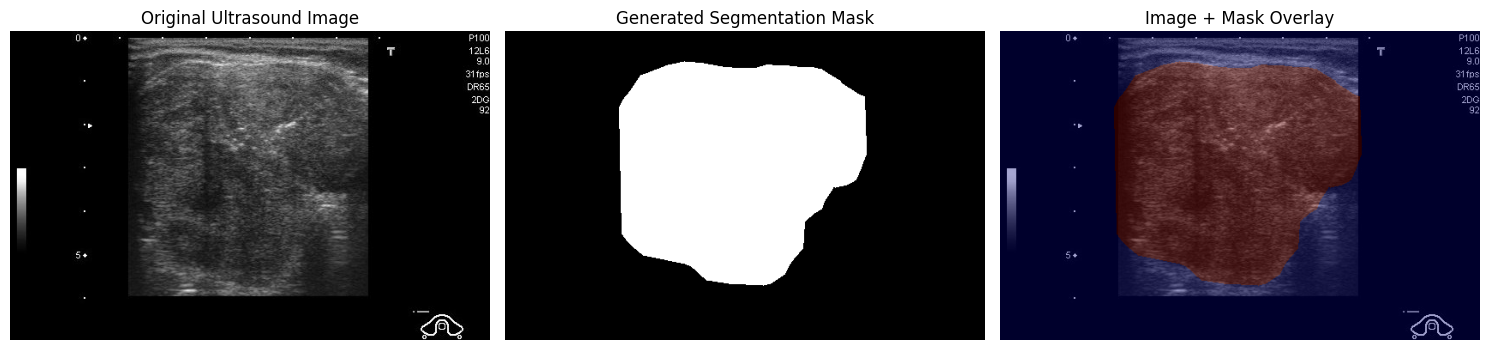

Case: 1
Image: 1_1.jpg
Mask: 1_1_mask.png
Image size: (560, 360)
Annotation points: 64


In [9]:
# ============================================================
# Step 8 - Visual Verification of Ultrasound Masks
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

# Select first valid annotated sample
sample = mask_df[mask_df["has_annotation"] == True].iloc[0]

image_path = Path(sample["image_path"])
mask_path = Path(sample["mask_path"])

# Load image and mask
image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

# Display
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original image
axes[0].imshow(image)
axes[0].set_title("Original Ultrasound Image")
axes[0].axis("off")

# Mask
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Generated Segmentation Mask")
axes[1].axis("off")

# Overlay
axes[2].imshow(image)
axes[2].imshow(mask, cmap="jet", alpha=0.35)
axes[2].set_title("Image + Mask Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Case:", sample["case_number"])
print("Image:", sample["image_filename"])
print("Mask:", sample["mask_filename"])
print("Image size:", image.size)
print("Annotation points:", sample["num_points"])

In [10]:
# ============================================================
# Step 9 - Ultrasound Image Preprocessing
# ============================================================

from pathlib import Path
from PIL import Image
import pandas as pd

# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

PROCESSED_ULTRASOUND_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "processed"
    / "ultrasound"
)

PROCESSED_IMAGES_DIR = (
    PROCESSED_ULTRASOUND_DIR
    / "images"
)

PROCESSED_MASKS_DIR = (
    PROCESSED_ULTRASOUND_DIR
    / "processed_masks"
)

PROCESSED_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PROCESSED_MASKS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Image size
# ------------------------------------------------------------

IMAGE_SIZE = (224, 224)

print("Target image size:", IMAGE_SIZE)

# ------------------------------------------------------------
# Use only valid annotated samples
# ------------------------------------------------------------

valid_mask_df = mask_df[
    mask_df["has_annotation"] == True
].copy()

print("Valid annotated images:", len(valid_mask_df))

# ------------------------------------------------------------
# Process images and masks
# ------------------------------------------------------------

processed_rows = []

failed_count = 0

for _, row in valid_mask_df.iterrows():

    image_path = Path(row["image_path"])
    mask_path = Path(row["mask_path"])

    try:
        # Load image
        image = Image.open(
            image_path
        ).convert("RGB")

        # Load mask
        mask = Image.open(
            mask_path
        ).convert("L")

        # Resize image
        image_resized = image.resize(
            IMAGE_SIZE,
            Image.Resampling.BILINEAR
        )

        # Resize mask using nearest-neighbor
        mask_resized = mask.resize(
            IMAGE_SIZE,
            Image.Resampling.NEAREST
        )

        # ----------------------------------------------------
        # Save processed image
        # ----------------------------------------------------

        processed_image_path = (
            PROCESSED_IMAGES_DIR
            / image_path.name
        )

        image_resized.save(
            processed_image_path,
            quality=95
        )

        # ----------------------------------------------------
        # Save processed mask
        # ----------------------------------------------------

        processed_mask_filename = (
            f"{image_path.stem}_mask.png"
        )

        processed_mask_path = (
            PROCESSED_MASKS_DIR
            / processed_mask_filename
        )

        mask_resized.save(
            processed_mask_path
        )

        # ----------------------------------------------------
        # Save metadata
        # ----------------------------------------------------

        processed_rows.append({
            "case_number": row["case_number"],
            "image_number": row["image_number"],
            "image_filename": image_path.name,
            "processed_image_path": str(
                processed_image_path
            ),
            "processed_mask_path": str(
                processed_mask_path
            ),
            "width": IMAGE_SIZE[0],
            "height": IMAGE_SIZE[1],
            "num_points": row["num_points"]
        })

    except Exception as error:

        failed_count += 1

        print(
            "Failed:",
            image_path.name,
            "| Error:",
            error
        )

# ------------------------------------------------------------
# Create processed dataset manifest
# ------------------------------------------------------------

processed_df = pd.DataFrame(
    processed_rows
)

PROCESSED_MANIFEST_PATH = (
    PROCESSED_ULTRASOUND_DIR
    / "processed_manifest.csv"
)

processed_df.to_csv(
    PROCESSED_MANIFEST_PATH,
    index=False,
    encoding="utf-8"
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nPreprocessing completed successfully.")

print("Images processed:", len(processed_df))
print("Images failed:", failed_count)

print("\nProcessed image size:")
print(
    processed_df[
        ["width", "height"]
    ].drop_duplicates()
)

print("\nManifest saved:")
print(PROCESSED_MANIFEST_PATH)

print("\nSample:")
display(
    processed_df.head(10)
)

Target image size: (224, 224)
Valid annotated images: 466

Preprocessing completed successfully.
Images processed: 466
Images failed: 0

Processed image size:
   width  height
0    224     224

Manifest saved:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\processed_manifest.csv

Sample:


,case_number,image_number,image_filename,processed_image_path,processed_mask_path,width,height,num_points
0,1,1,1_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,64
1,1,2,1_2.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,61
2,2,1,2_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,50
3,3,1,3_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,30
4,4,1,4_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,75
5,5,1,5_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,55
6,6,1,6_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,33
7,7,1,7_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,50
8,8,1,8_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,49
9,9,1,9_1.jpg,D:\MultiModalCancerTherapy_Structure\MultiModa...,D:\MultiModalCancerTherapy_Structure\MultiModa...,224,224,31


In [11]:
# ============================================================
# Step 10 - Case-Level Train / Validation / Test Split
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

split_df = processed_df.copy()

print("Total processed images:", len(split_df))
print("Unique cases:", split_df["case_number"].nunique())

# ------------------------------------------------------------
# First split:
# 80% Train + 20% Temporary
# ------------------------------------------------------------

gss_train = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    gss_train.split(
        split_df,
        groups=split_df["case_number"]
    )
)

train_df = split_df.iloc[train_idx].copy()
temp_df = split_df.iloc[temp_idx].copy()

# ------------------------------------------------------------
# Second split:
# Temporary -> 50% Validation + 50% Test
# Final = 80% Train / 10% Validation / 10% Test
# ------------------------------------------------------------

gss_val_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_val_test.split(
        temp_df,
        groups=temp_df["case_number"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# ------------------------------------------------------------
# Verify case separation
# ------------------------------------------------------------

train_cases = set(train_df["case_number"])
val_cases = set(val_df["case_number"])
test_cases = set(test_df["case_number"])

print("\nDataset split:")
print("-" * 50)

print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))

print("\nUnique cases:")
print("Training cases   :", len(train_cases))
print("Validation cases :", len(val_cases))
print("Testing cases    :", len(test_cases))

print("\nCase overlap check:")
print("Train ∩ Validation:", len(train_cases & val_cases))
print("Train ∩ Test      :", len(train_cases & test_cases))
print("Validation ∩ Test :", len(val_cases & test_cases))

# ------------------------------------------------------------
# Save split manifests
# ------------------------------------------------------------

SPLIT_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "processed"
    / "ultrasound"
)

TRAIN_SPLIT_PATH = SPLIT_DIR / "train_manifest.csv"
VAL_SPLIT_PATH = SPLIT_DIR / "validation_manifest.csv"
TEST_SPLIT_PATH = SPLIT_DIR / "test_manifest.csv"

train_df.to_csv(
    TRAIN_SPLIT_PATH,
    index=False,
    encoding="utf-8"
)

val_df.to_csv(
    VAL_SPLIT_PATH,
    index=False,
    encoding="utf-8"
)

test_df.to_csv(
    TEST_SPLIT_PATH,
    index=False,
    encoding="utf-8"
)

print("\nSplit manifests saved:")
print(TRAIN_SPLIT_PATH)
print(VAL_SPLIT_PATH)
print(TEST_SPLIT_PATH)

Total processed images: 466
Unique cases: 380

Dataset split:
--------------------------------------------------
Training images   : 366
Validation images : 44
Testing images    : 56

Unique cases:
Training cases   : 304
Validation cases : 38
Testing cases    : 38

Case overlap check:
Train ∩ Validation: 0
Train ∩ Test      : 0
Validation ∩ Test : 0

Split manifests saved:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\train_manifest.csv
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\validation_manifest.csv
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\processed\ultrasound\test_manifest.csv


In [12]:
# ============================================================
# Step 11 - Verify Jupyter / PyTorch Environment
# ============================================================

import sys
from pathlib import Path

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

# ------------------------------------------------------------
# Check PyTorch
# ------------------------------------------------------------

try:
    import torch

    print("\nPyTorch:")
    print("Version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("Using CPU")

except Exception as error:
    print("\nPyTorch import failed:")
    print(type(error).__name__, ":", error)

# ------------------------------------------------------------
# Check torchvision
# ------------------------------------------------------------

try:
    import torchvision

    print("\ntorchvision:")
    print("Version:", torchvision.__version__)

except Exception as error:
    print("\ntorchvision import failed:")
    print(type(error).__name__, ":", error)

# ------------------------------------------------------------
# Check PIL
# ------------------------------------------------------------

try:
    from PIL import Image

    print("\nPillow:")
    print("Version check successful")

except Exception as error:
    print("\nPillow import failed:")
    print(type(error).__name__, ":", error)

Python executable:
C:\Users\madhu\AppData\Local\Programs\Python\Python310\python.exe

Python version:
3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]

PyTorch:
Version: 2.13.0+cpu
CUDA available: False
Using CPU

torchvision:
Version: 0.28.0+cpu

Pillow:
Version check successful


In [13]:
# ============================================================
# Step 12 - Create PyTorch Dataset and DataLoaders
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

# ------------------------------------------------------------
# Dataset class
# ------------------------------------------------------------

class UltrasoundSegmentationDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load image
        image = Image.open(
            row["processed_image_path"]
        ).convert("RGB")

        # Load mask
        mask = Image.open(
            row["processed_mask_path"]
        ).convert("L")

        # Convert to numpy
        image_array = np.array(
            image,
            dtype=np.float32
        )

        mask_array = np.array(
            mask,
            dtype=np.float32
        )

        # Normalize image to [0, 1]
        image_array = image_array / 255.0

        # Convert mask to binary
        mask_array = (
            mask_array > 127
        ).astype(np.float32)

        # HWC -> CHW
        image_tensor = torch.tensor(
            image_array,
            dtype=torch.float32
        ).permute(2, 0, 1)

        # Add channel dimension to mask
        mask_tensor = torch.tensor(
            mask_array,
            dtype=torch.float32
        ).unsqueeze(0)

        return image_tensor, mask_tensor


# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_dataset = UltrasoundSegmentationDataset(train_df)
val_dataset = UltrasoundSegmentationDataset(val_df)
test_dataset = UltrasoundSegmentationDataset(test_df)

# ------------------------------------------------------------
# Create DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# Test one batch
# ------------------------------------------------------------

images, masks = next(iter(train_loader))

print("Dataset / DataLoader created successfully.")

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

print("\nBatch image shape:")
print(images.shape)

print("\nBatch mask shape:")
print(masks.shape)

print("\nImage value range:")
print(
    float(images.min()),
    "to",
    float(images.max())
)

print("\nMask unique values:")
print(torch.unique(masks))

print("\nDevice:")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

Dataset / DataLoader created successfully.

Training samples: 366
Validation samples: 44
Testing samples: 56

Batch image shape:
torch.Size([8, 3, 224, 224])

Batch mask shape:
torch.Size([8, 1, 224, 224])

Image value range:
0.0 to 1.0

Mask unique values:
tensor([0., 1.])

Device:
cpu


In [14]:
# ============================================================
# Step 13 - Lightweight U-Net Model
# ============================================================

import torch
import torch.nn as nn


# ------------------------------------------------------------
# Double Convolution Block
# ------------------------------------------------------------

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ------------------------------------------------------------
# Lightweight U-Net
# ------------------------------------------------------------

class UNetSmall(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(
            32,
            16,
            kernel_size=2,
            stride=2
        )
        self.dec1 = DoubleConv(32, 16)

        # Final output
        self.output = nn.Conv2d(
            16,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        p1 = self.pool(e1)

        e2 = self.enc2(p1)
        p2 = self.pool(e2)

        e3 = self.enc3(p2)
        p3 = self.pool(e3)

        # Bottleneck
        b = self.bottleneck(p3)

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

segmentation_model = UNetSmall(
    in_channels=3,
    out_channels=1
).to(device)


# ------------------------------------------------------------
# Model information
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in segmentation_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in segmentation_model.parameters()
    if parameter.requires_grad
)

print("Lightweight U-Net created successfully.")

print("\nDevice:")
print(device)

print("\nTotal parameters:")
print(f"{total_parameters:,}")

print("\nTrainable parameters:")
print(f"{trainable_parameters:,}")


# ------------------------------------------------------------
# Test forward pass
# ------------------------------------------------------------

sample_images, sample_masks = next(
    iter(train_loader)
)

sample_images = sample_images.to(device)

with torch.no_grad():
    sample_output = segmentation_model(
        sample_images
    )

print("\nInput shape:")
print(sample_images.shape)

print("\nOutput shape:")
print(sample_output.shape)

print("\nExpected output shape:")
print(sample_masks.shape)

Lightweight U-Net created successfully.

Device:
cpu

Total parameters:
483,441

Trainable parameters:
483,441

Input shape:
torch.Size([8, 3, 224, 224])

Output shape:
torch.Size([8, 1, 224, 224])

Expected output shape:
torch.Size([8, 1, 224, 224])


In [15]:
# ============================================================
# Step 14 - Dice Loss + BCE Loss
# ============================================================

import torch
import torch.nn as nn

class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.view(
            probabilities.size(0), -1
        )

        targets = targets.view(
            targets.size(0), -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
            + self.smooth
        )

        return 1.0 - dice.mean()


bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()

print("Dice Loss created.")
print("BCE Loss created.")

Dice Loss created.
BCE Loss created.


In [16]:
# ============================================================
# Step 15 - Train Lightweight U-Net
# ============================================================

import torch
import time

# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

EPOCHS = 10
LEARNING_RATE = 1e-3

optimizer = torch.optim.Adam(
    segmentation_model.parameters(),
    lr=LEARNING_RATE
)

print("Training configuration:")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Device:", device)

# ------------------------------------------------------------
# Combined loss
# ------------------------------------------------------------

def combined_loss(logits, targets):
    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return bce + dice


# ------------------------------------------------------------
# Validation function
# ------------------------------------------------------------

def validate_model(model, loader):

    model.eval()

    total_loss = 0.0
    batches = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = combined_loss(
                outputs,
                masks
            )

            total_loss += loss.item()
            batches += 1

    return total_loss / max(batches, 1)


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

training_history = []

print("\nStarting U-Net training...\n")

for epoch in range(EPOCHS):

    start_time = time.time()

    segmentation_model.train()

    running_loss = 0.0
    batches = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = segmentation_model(images)

        # Calculate loss
        loss = combined_loss(
            outputs,
            masks
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()
        batches += 1

    train_loss = (
        running_loss / max(batches, 1)
    )

    # Validation
    val_loss = validate_model(
        segmentation_model,
        val_loader
    )

    elapsed = time.time() - start_time

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

print("\nTraining completed successfully.")

Training configuration:
Epochs: 10
Learning rate: 0.001
Device: cpu

Starting U-Net training...

Epoch [1/10] Train Loss: 1.2924 | Val Loss: 1.2696 | Time: 53.1s
Epoch [2/10] Train Loss: 1.1336 | Val Loss: 1.0602 | Time: 51.9s
Epoch [3/10] Train Loss: 1.0142 | Val Loss: 0.9301 | Time: 51.8s
Epoch [4/10] Train Loss: 0.9192 | Val Loss: 1.1885 | Time: 52.0s
Epoch [5/10] Train Loss: 0.8400 | Val Loss: 0.8340 | Time: 52.0s
Epoch [6/10] Train Loss: 0.7632 | Val Loss: 0.8027 | Time: 52.3s
Epoch [7/10] Train Loss: 0.6996 | Val Loss: 1.0982 | Time: 52.1s
Epoch [8/10] Train Loss: 0.6582 | Val Loss: 0.9923 | Time: 51.9s
Epoch [9/10] Train Loss: 0.6073 | Val Loss: 1.3652 | Time: 52.1s
Epoch [10/10] Train Loss: 0.5834 | Val Loss: 0.7106 | Time: 51.8s

Training completed successfully.


In [17]:
# ============================================================
# Step 16 - Dice Score and IoU Evaluation
# ============================================================

import torch
import numpy as np

def calculate_dice(predictions, targets, smooth=1e-7):
    """
    Calculate Dice coefficient for binary segmentation.
    """

    predictions = predictions.reshape(
        predictions.shape[0], -1
    )

    targets = targets.reshape(
        targets.shape[0], -1
    )

    intersection = (
        predictions * targets
    ).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        predictions.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return dice.mean().item()


def calculate_iou(predictions, targets, smooth=1e-7):
    """
    Calculate Intersection over Union.
    """

    predictions = predictions.reshape(
        predictions.shape[0], -1
    )

    targets = targets.reshape(
        targets.shape[0], -1
    )

    intersection = (
        predictions * targets
    ).sum(dim=1)

    union = (
        predictions
        + targets
        - predictions * targets
    ).sum(dim=1)

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    return iou.mean().item()


# ------------------------------------------------------------
# Evaluate validation dataset
# ------------------------------------------------------------

segmentation_model.eval()

val_dice_scores = []
val_iou_scores = []

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = segmentation_model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).float()

        dice = calculate_dice(
            predictions,
            masks
        )

        iou = calculate_iou(
            predictions,
            masks
        )

        val_dice_scores.append(dice)
        val_iou_scores.append(iou)


mean_val_dice = np.mean(val_dice_scores)
mean_val_iou = np.mean(val_iou_scores)

print("Validation Segmentation Results")
print("=" * 50)

print(f"Dice Score : {mean_val_dice:.4f}")
print(f"IoU Score   : {mean_val_iou:.4f}")

Validation Segmentation Results
Dice Score : 0.5393
IoU Score   : 0.4008
